# Keplerova úloha a trajektorie v gravitačním poli

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# na riesenie diferenciálnych rovníc použijeme funkciu solve_ivp z knižnice scipy.integrate
from scipy.integrate import solve_ivp

%matplotlib widget


## Jedno teleso v centralnom poli

Napr. planeta v poli Slnka. Ako pociatocnu podmienku berieme pohyb v smere osy x s jednotkovou velkostou a premenlivu vzdialenost od stredu

(-20.0, 5.0)

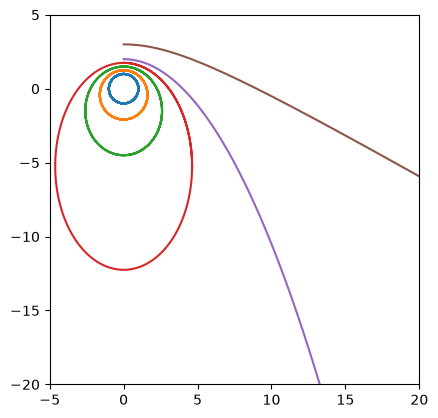

In [2]:
G = 1
M = 1

def akcelerace(t, rv):
    x, y, vx, vy = rv
    _r = np.sqrt(x**2 + y**2)
    a_x = - G*M/_r**3 * x
    a_y = - G*M/_r**3 * y

    return [vx, vy, a_x, a_y]

fig, ax = plt.subplots()
ax.set_aspect("equal")

v0 = 1.0
for r0 in [1, 1.25, 1.5, 1.75, 2, 3]:
    T_max = 12*2*np.pi*r0/v0
    t_eval = np.linspace(0, T_max, 1000)

    sol = solve_ivp(akcelerace, (0, T_max), y0=(0, r0, v0, 0), dense_output=True, method="DOP853")
    traj = sol.sol(t_eval)
    ax.plot(traj[0,:], traj[1,:])

ax.set_xlim(-5, 20)
ax.set_ylim(-20, 5)

## Dve telesa v zajomnom poli
Pociatocna je podobna: relatívna rýchlosť planét je 1, ale ťažisko sa nehýbe a nepredpokladáme, že jedna je omnoho tažšia, než tá druhá

(-5.0, 5.0)

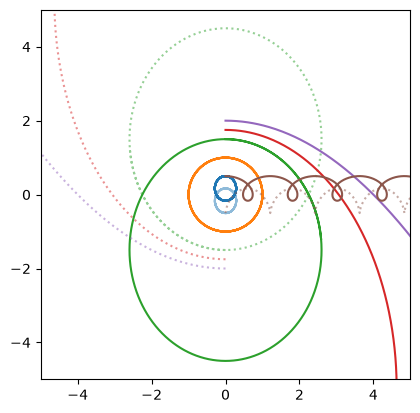

In [3]:
G = 1
M = 1
m=1

def akcelerace2(t, rv):
    x1, y1, vx1, vy1 = rv[:4]
    x2, y2, vx2, vy2 = rv[4:]
    dx = x1 - x2
    dy = y1 - y2
    _r = np.sqrt(dx**2 + dy**2)
    F1x = - G*M*m/_r**3 * dx
    F1y = - G*M*m/_r**3 * dy

    a1_x = F1x / m
    a1_y = F1y / m

    a2_x = - F1x / M
    a2_y = - F1y / M

    return [vx1, vy1, a1_x, a1_y, vx2, vy2, a2_x, a2_y]

fig, ax = plt.subplots()
ax.set_aspect("equal")

v0 = 1
for r0 in [1, 2, 3, 3.5, 4]:
    T_max = 4*2*np.pi*r0/v0
    t_eval = np.linspace(0, T_max, 1000)

    sol = solve_ivp(akcelerace2, (0, T_max), y0=(0, r0/2, v0/2, 0, 0, -r0/2, -v0/2, 0), dense_output=True, method="DOP853")
    traj = sol.sol(t_eval)
    l = ax.plot(traj[0,:], traj[1,:])
    ax.plot(traj[4,:], traj[5,:], ':', color=l[-1].get_color(), alpha=0.5)


# Pripad, kedy celkova pociatocna hybnost je nenulova
# -- planety obiehaju okolo spolocneho pohybujuceho sa taziska
r0 = 1
T_max = 4*2*np.pi*r0/v0
t_eval = np.linspace(0, T_max, 1000)
sol = solve_ivp(akcelerace2, (0, T_max), y0=(0, r0/2, v0, 0, 0, -r0/2, 0, 0), dense_output=True, method="DOP853")
traj = sol.sol(t_eval)
l = ax.plot(traj[0,:], traj[1,:])
ax.plot(traj[4,:], traj[5,:], ':', color=l[-1].get_color(), alpha=0.5)

ax.set_xlim(-5, 5)
ax.set_ylim(-5, 5)

## Tri telesá

Výsledok je chaotický

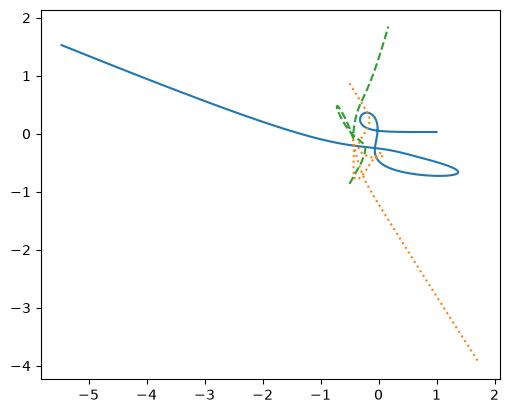

In [4]:
G = 1
m1 = 1
m2 = 2
m3 = 3

def akcelerace3(t, rv):
    x1, y1, vx1, vy1 = rv[:4]
    x2, y2, vx2, vy2 = rv[4:8]
    x3, y3, vx3, vy3 = rv[8:]

    dx12 = x1 - x2
    dy12 = y1 - y2

    dx13 = x1 - x3
    dy13 = y1 - y3

    dx32 = x3 - x2
    dy32 = y3 - y2

    _r12 = np.sqrt(dx12**2 + dy12**2)
    _r13 = np.sqrt(dx13**2 + dy13**2)
    _r32 = np.sqrt(dx32**2 + dy32**2)

    F12x = - G*M*m/_r12**3 * dx12
    F12y = - G*M*m/_r12**3 * dy12

    F13x = - G*M*m/_r13**3 * dx13
    F13y = - G*M*m/_r13**3 * dy13

    F32x = - G*M*m/_r32**3 * dx32
    F32y = - G*M*m/_r32**3 * dy32

    F1x = F12x + F13x
    F1y = F12y + F13y

    F2x = -F12x - F32x
    F2y = -F12y - F32y

    F3x = -F13x + F32x
    F3y = -F13y + F32y

    a1_x = F1x / m1
    a1_y = F1y / m1

    a2_x = F2x / m2
    a2_y = F2y / m2

    a3_x = F3x / m3
    a3_y = F3y / m3

    return [vx1, vy1, a1_x, a1_y, vx2, vy2, a2_x, a2_y, vx3, vy3, a3_x, a3_y]

fig, ax = plt.subplots()
ax.set_aspect("equal")

for r0 in [1]:
    x1, y1 = r0, np.random.rand() * 0.05 * r0
    x2, y2 = r0*np.cos(2*np.pi/3), r0*np.sin(2*np.pi/3) + np.random.rand() * 0.05 * r0
    x3, y3 = r0*np.cos(2*2*np.pi/3), r0*np.sin(2*2*np.pi/3) + np.random.rand() * 0.05 * r0

    # pociatocne polohy a rychlosti, rychlosti vsetky 0
    _y0 = [x1, y1, 0, 0, x2, y2, 0, 0, x3, y3, 0, 0]

    T_max = 10
    t_eval = np.linspace(0, T_max, 1000)

    sol = solve_ivp(akcelerace3, (0, T_max), y0=_y0, dense_output=True, method="DOP853")
    traj = sol.sol(t_eval)
    ax.plot(traj[0,:], traj[1,:])
    ax.plot(traj[4,:], traj[5,:], ':')
    ax.plot(traj[8,:], traj[9,:], '--')

# ax.set_xlim(-5, 5)
# ax.set_ylim(-5, 5)

## Lagrangeove body

(-2.5, 2.5)

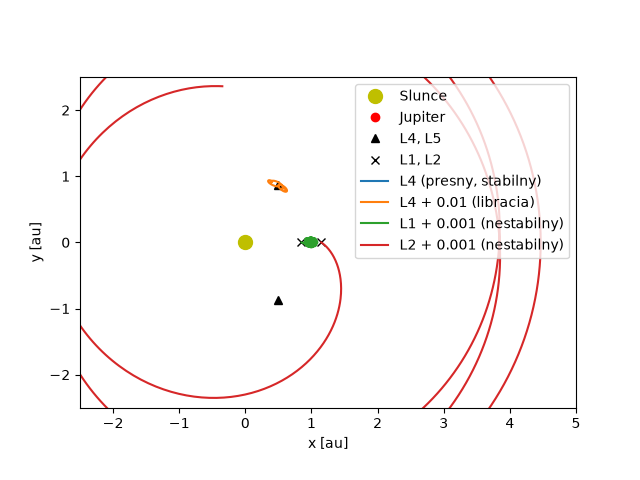

In [70]:
G = 1
m1 = 1 # Slunce
m2 = 0.01 # napr. Jupiter
m3 = 1 # testovacia castica (e.g., satelit)

r12 = 1.0
omega = np.sqrt(G*(m1+m2)/r12**3) # obezna uhlova frekvence

def akceleraceLB(t, rv):
    x3, y3, vx3, vy3 = rv

    dx13 = x3 - x1
    dy13 = y3 - y1

    dx32 = x3 - x2
    dy32 = y3 - y2

    _r13 = np.sqrt(dx13**2 + dy13**2)
    _r32 = np.sqrt(dx32**2 + dy32**2)

    F13x = - G*m1*m3/_r13**3 * dx13
    F13y = - G*m1*m3/_r13**3 * dy13

    F32x = - G*m3*m2/_r32**3 * dx32
    F32y = - G*m3*m2/_r32**3 * dy32

    F3x = F13x + F32x + 2*m3*omega*vy3 + m3*omega**2*x3
    F3y = F13y + F32y - 2*m3*omega*vx3 + m3*omega**2*y3

    a3_x = F3x / m3
    a3_y = F3y / m3

    return [vx3, vy3, a3_x, a3_y]

fig, ax = plt.subplots()
ax.set_aspect("equal")

from scipy.optimize import root_scalar

# tazisko v strede
x1, y1 = -m2 / (m1 + m2), 0.0
x2, y2 = m1 / (m1 + m2), 0.0

# L4 a L5 (rovnostranne trojuholniky)
x_L = x1 + 0.5 * r12
y_L = np.sqrt(3)/2 * r12

# Kolinearne Lagrangeove body L1 a L2 (pozdlz osi x, y=0)
def F_eff_x(x):
    f1 = - G * m1 * np.sign(x - x1) / (x - x1)**2
    f2 = - G * m2 * np.sign(x - x2) / (x - x2)**2
    f_cf = omega**2 * x
    return f1 + f2 + f_cf

x_L1 = root_scalar(F_eff_x, bracket=[x1 + 0.01, x2 - 1e-4]).root
x_L2 = root_scalar(F_eff_x, bracket=[x2 + 1e-4, x2 + 1.0]).root

# Polohy telies a Lagrangeovych bodov
ax.plot(x1, y1, 'yo', markersize=10, label='Slunce')
ax.plot(x2, y2, 'ro', markersize=6, label='Jupiter')
ax.plot([x_L, x_L], [y_L, -y_L], 'k^', markersize=6, label='L4, L5')
ax.plot([x_L1, x_L2], [0, 0], 'kx', markersize=6, label='L1, L2')

for x3s in [
    (x_L, y_L, "L4 (presny, stabilny)"),
    (x_L + 0.01, y_L, "L4 + 0.01 (libracia)"),
    (x_L1 + 0.001, 0, "L1 + 0.001 (nestabilny)"),
    (x_L2 + 0.001, 0, "L2 + 0.001 (nestabilny)")
    ]:
    x3, y3, label = x3s

    # pociatocne polohy a rychlosti, rychlosti vsetky 0
    _y0 = [x3, y3, 0, 0]

    T_max = 30
    t_eval = np.linspace(0, T_max, 1000)

    sol = solve_ivp(akceleraceLB, (0, T_max), y0=_y0, dense_output=True)
    traj = sol.sol(t_eval)
    ax.plot(traj[0,:], traj[1,:], label=label)


ax.set_xlabel('x [au]')
ax.set_ylabel('y [au]')
ax.legend(loc='upper right')

ax.set_xlim(-2.5, 5)
ax.set_ylim(-2.5, 2.5)
